# ТК 5-6 (ПР3): kNN — качество красного вина
Код повторяет приёмы workbook `docs/Текущий контроль 3.ipynb` (ячейки 5/7/9/12/20/39–42); отклонения помечены комментарием `# отклонение:`. Оригиналы в `docs/` не меняются. `random_state=42` — отклонение (в workbook сид не задан), нужно для воспроизводимости.

In [1]:
#Импорт необходимых библиотек (workbook, ячейка 5; без mlxtend/datasets — они только для Iris/2D-карт)
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

%matplotlib inline
plt.rcParams["figure.figsize"] = (10,5)

In [2]:
#Загрузка датасета (workbook, ячейка 7: df + df.head())
df = pd.read_csv('docs/winequality-red.csv')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
#Описание набора данных (workbook, ячейка 9: df.info())
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


missing cells: 0
full-row duplicates: 240
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


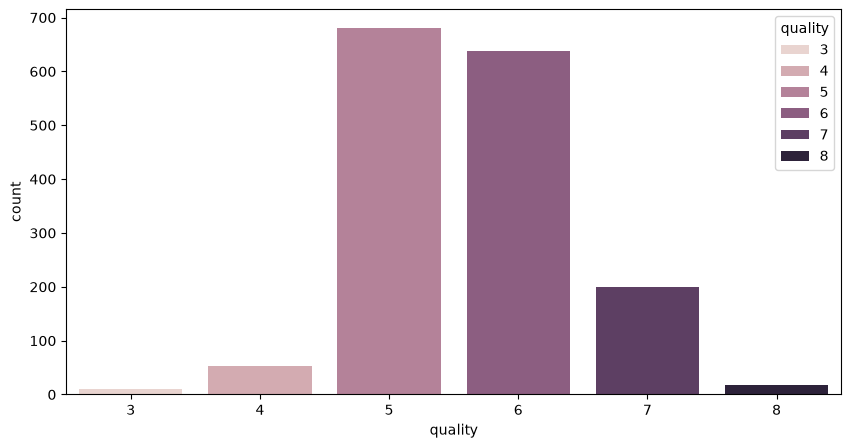

In [4]:
#Баланс классов (workbook, ячейка 12: sns.countplot)
sns.countplot(x='quality', hue='quality', data=df)

# отклонение: проверка «плохого датасета» (требование препода)
print('missing cells:', int(df.isna().sum().sum()))
print('full-row duplicates:', int(df.duplicated().sum()))
print(df['quality'].value_counts().sort_index())

In [5]:
# Helper functions (workbook, ячейка 20 — дословно)
def display_confusion_matrix(
    matrix, labels=None,
    title="Confusion Matrix",
    xlabel="Predicted",
    ylabel="Actual",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    if labels is None:
        labels = [""]*len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax-vmin) / 2.
    fig,ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row,col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row,col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    tick_marks = np.arange(len(labels))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

In [6]:
#Разделение на обучающий/тестовый набор (workbook, ячейка 39)
X = df.drop(['quality'], axis=1)
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

In [7]:
#Модель kNN (workbook, ячейка 40)
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](6,)","[3,4,5,6,7,8]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [8]:
#Оценка: отчёт + accuracy (workbook, ячейка 41; порядок аргументов исправлен: в workbook (preds, y_test))
preds = knn.predict(X_test)

print(classification_report(y_test, preds))
print('accuracy:', accuracy_score(y_test, preds))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         3
           4       0.00      0.00      0.00        16
           5       0.53      0.61      0.57       204
           6       0.47      0.52      0.49       192
           7       0.34      0.18      0.24        60
           8       0.00      0.00      0.00         5

    accuracy                           0.49       480
   macro avg       0.22      0.22      0.22       480
weighted avg       0.46      0.49      0.47       480

accuracy: 0.4895833333333333


[[125  71   7   1   0   0]
 [ 81  99  12   0   0   0]
 [ 18  30  11   1   0   0]
 [ 11   5   0   0   0   0]
 [  0   3   2   0   0   0]
 [  1   2   0   0   0   0]]


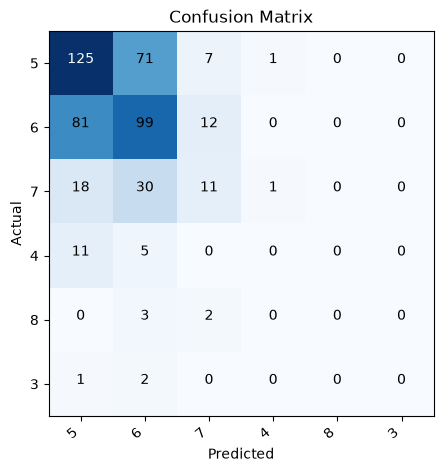

In [9]:
#Матрица путаницы (workbook, ячейка 42: labels=wine quality)
labels = y.unique()

matrix = confusion_matrix(y_test, preds, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, labels)

In [10]:
# отклонение: таблица per-class P/R/F1 (в workbook нет; нужно для сдачи)
import sys; sys.path.insert(0, '.')
from wine_knn import evaluate_knn
res = evaluate_knn('docs/winequality-red.csv')
for m in ('precision','recall','f1'):
    print('per-class ' + m + ':', {k: round(v,3) for k,v in res['per_class'][m].items()})
print('support_test:', res['per_class']['support_test'])
print('macro P/R/F1:', round(res['precision_macro'],4), round(res['recall_macro'],4), round(res['f1_macro'],4))
print('weighted P/R/F1:', round(res['precision_weighted'],4), round(res['recall_weighted'],4), round(res['f1_weighted'],4))
print('OvR AUC macro/weighted:', round(res['roc_auc_ovr_macro'],4), round(res['roc_auc_ovr_weighted'],4))
print('per-class OvR AUC:', {k: round(v,3) for k,v in res['per_class']['roc_auc_ovr'].items()})

per-class precision: {5: 0.53, 6: 0.471, 7: 0.344, 4: 0.0, 8: 0.0, 3: 0.0}
per-class recall: {5: 0.613, 6: 0.516, 7: 0.183, 4: 0.0, 8: 0.0, 3: 0.0}
per-class f1: {5: 0.568, 6: 0.493, 7: 0.239, 4: 0.0, 8: 0.0, 3: 0.0}
support_test: {5: 204, 6: 192, 7: 60, 4: 16, 8: 5, 3: 3}
macro P/R/F1: 0.2241 0.2186 0.2166
weighted P/R/F1: 0.4566 0.4896 0.4684
OvR AUC macro/weighted: 0.6173 0.6521
per-class OvR AUC: {5: 0.689, 6: 0.603, 7: 0.725, 4: 0.519, 8: 0.682, 3: 0.486}


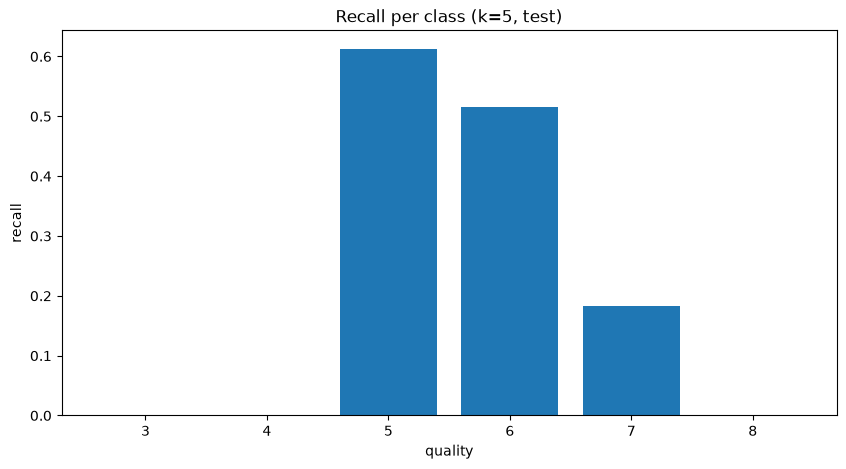

In [11]:
# отклонение: recall по классам для защиты
recall_by_class = res['per_class']['recall']
plt.bar(list(recall_by_class.keys()), list(recall_by_class.values()))
plt.xlabel('quality'); plt.ylabel('recall')
plt.title('Recall per class (k=5, test)'); plt.show()

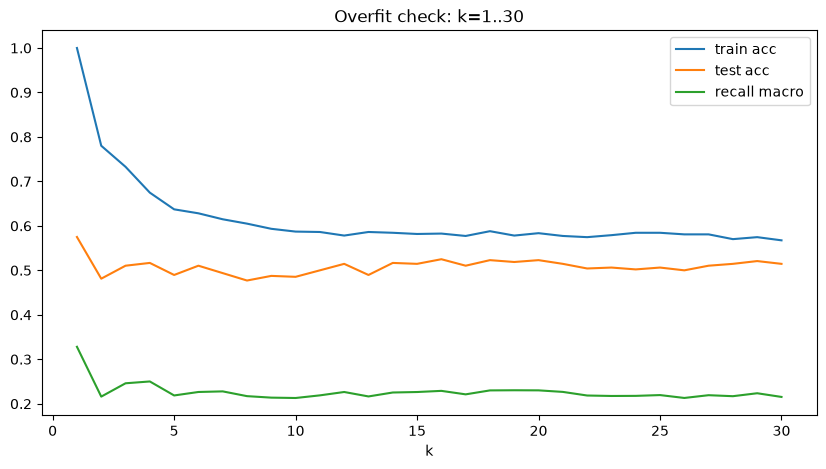

In [12]:
# отклонение: проверка обучения k=1..30 (в workbook один k)
from wine_knn import k_sweep
rows = k_sweep('docs/winequality-red.csv')
k_values = [row['k'] for row in rows]
train_accuracy = [row['train_accuracy'] for row in rows]
test_accuracy = [row['test_accuracy'] for row in rows]
recall_macro = [row['recall_macro'] for row in rows]
plt.plot(k_values, train_accuracy, label='train acc')
plt.plot(k_values, test_accuracy, label='test acc')
plt.plot(k_values, recall_macro, label='recall macro')
plt.xlabel('k'); plt.legend(); plt.title('Overfit check: k=1..30'); plt.show()

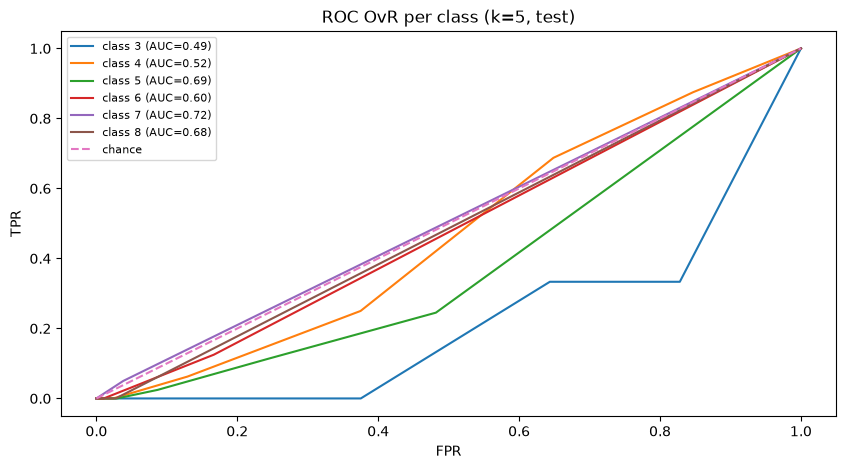

In [13]:
# отклонение: ROC OvR по классам (Дьяконов: AUC=доля верно упорядоченных пар)
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
classes = res['classes']
y_binarized = label_binarize(res['y_test'], classes=classes)
fig, ax = plt.subplots()
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_binarized[:, i], res['y_proba'][:, i])
    ax.plot(fpr, tpr, label=f'class {cls} (AUC={res["per_class"]["roc_auc_ovr"][cls]:.2f})')
ax.plot([0, 1], [0, 1], linestyle='--', label='chance')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(fontsize=8)
plt.title('ROC OvR per class (k=5, test)'); plt.show()

## Выводы
- kNN(k=5) без скейлинга: test accuracy ~0.49 при train ~0.64 — переобучение на малых k, разрыв виден на кривой k=1..30.
- Путаница в основном 5↔6 (мажоритарные классы); recall классов 3/4/8 ≈ 0 — в тесте их ~3/16/5 шт, kNN редкие классы не возвращает.
- Macro P/R/F1 ~0.22 против weighted ~0.46–0.49: расхождение — прямое следствие дисбаланса.
- OvR AUC macro ~0.62: ранжирование слабое; per-class AUC классов 3/8 нестабилен (малые выборки, см. Дьяконов про дисперсию AUC) — не использовать для ранжирования моделей.
- Масштабы признаков 0.01–289: для корректного kNN нужен StandardScaler (внутри Pipeline при CV); здесь осознанно оставлен протокол workbook без скейлинга.